C:\Users\julia\anaconda3\envs\rotokawa\Lib\site-packages\pygmt\helpers\decorators.py:598: FutureWarning: The 'map_scale' parameter has been deprecated since v0.19.0. Use 'Figure.scalebar' instead.
  return module_func(*args, **kwargs)


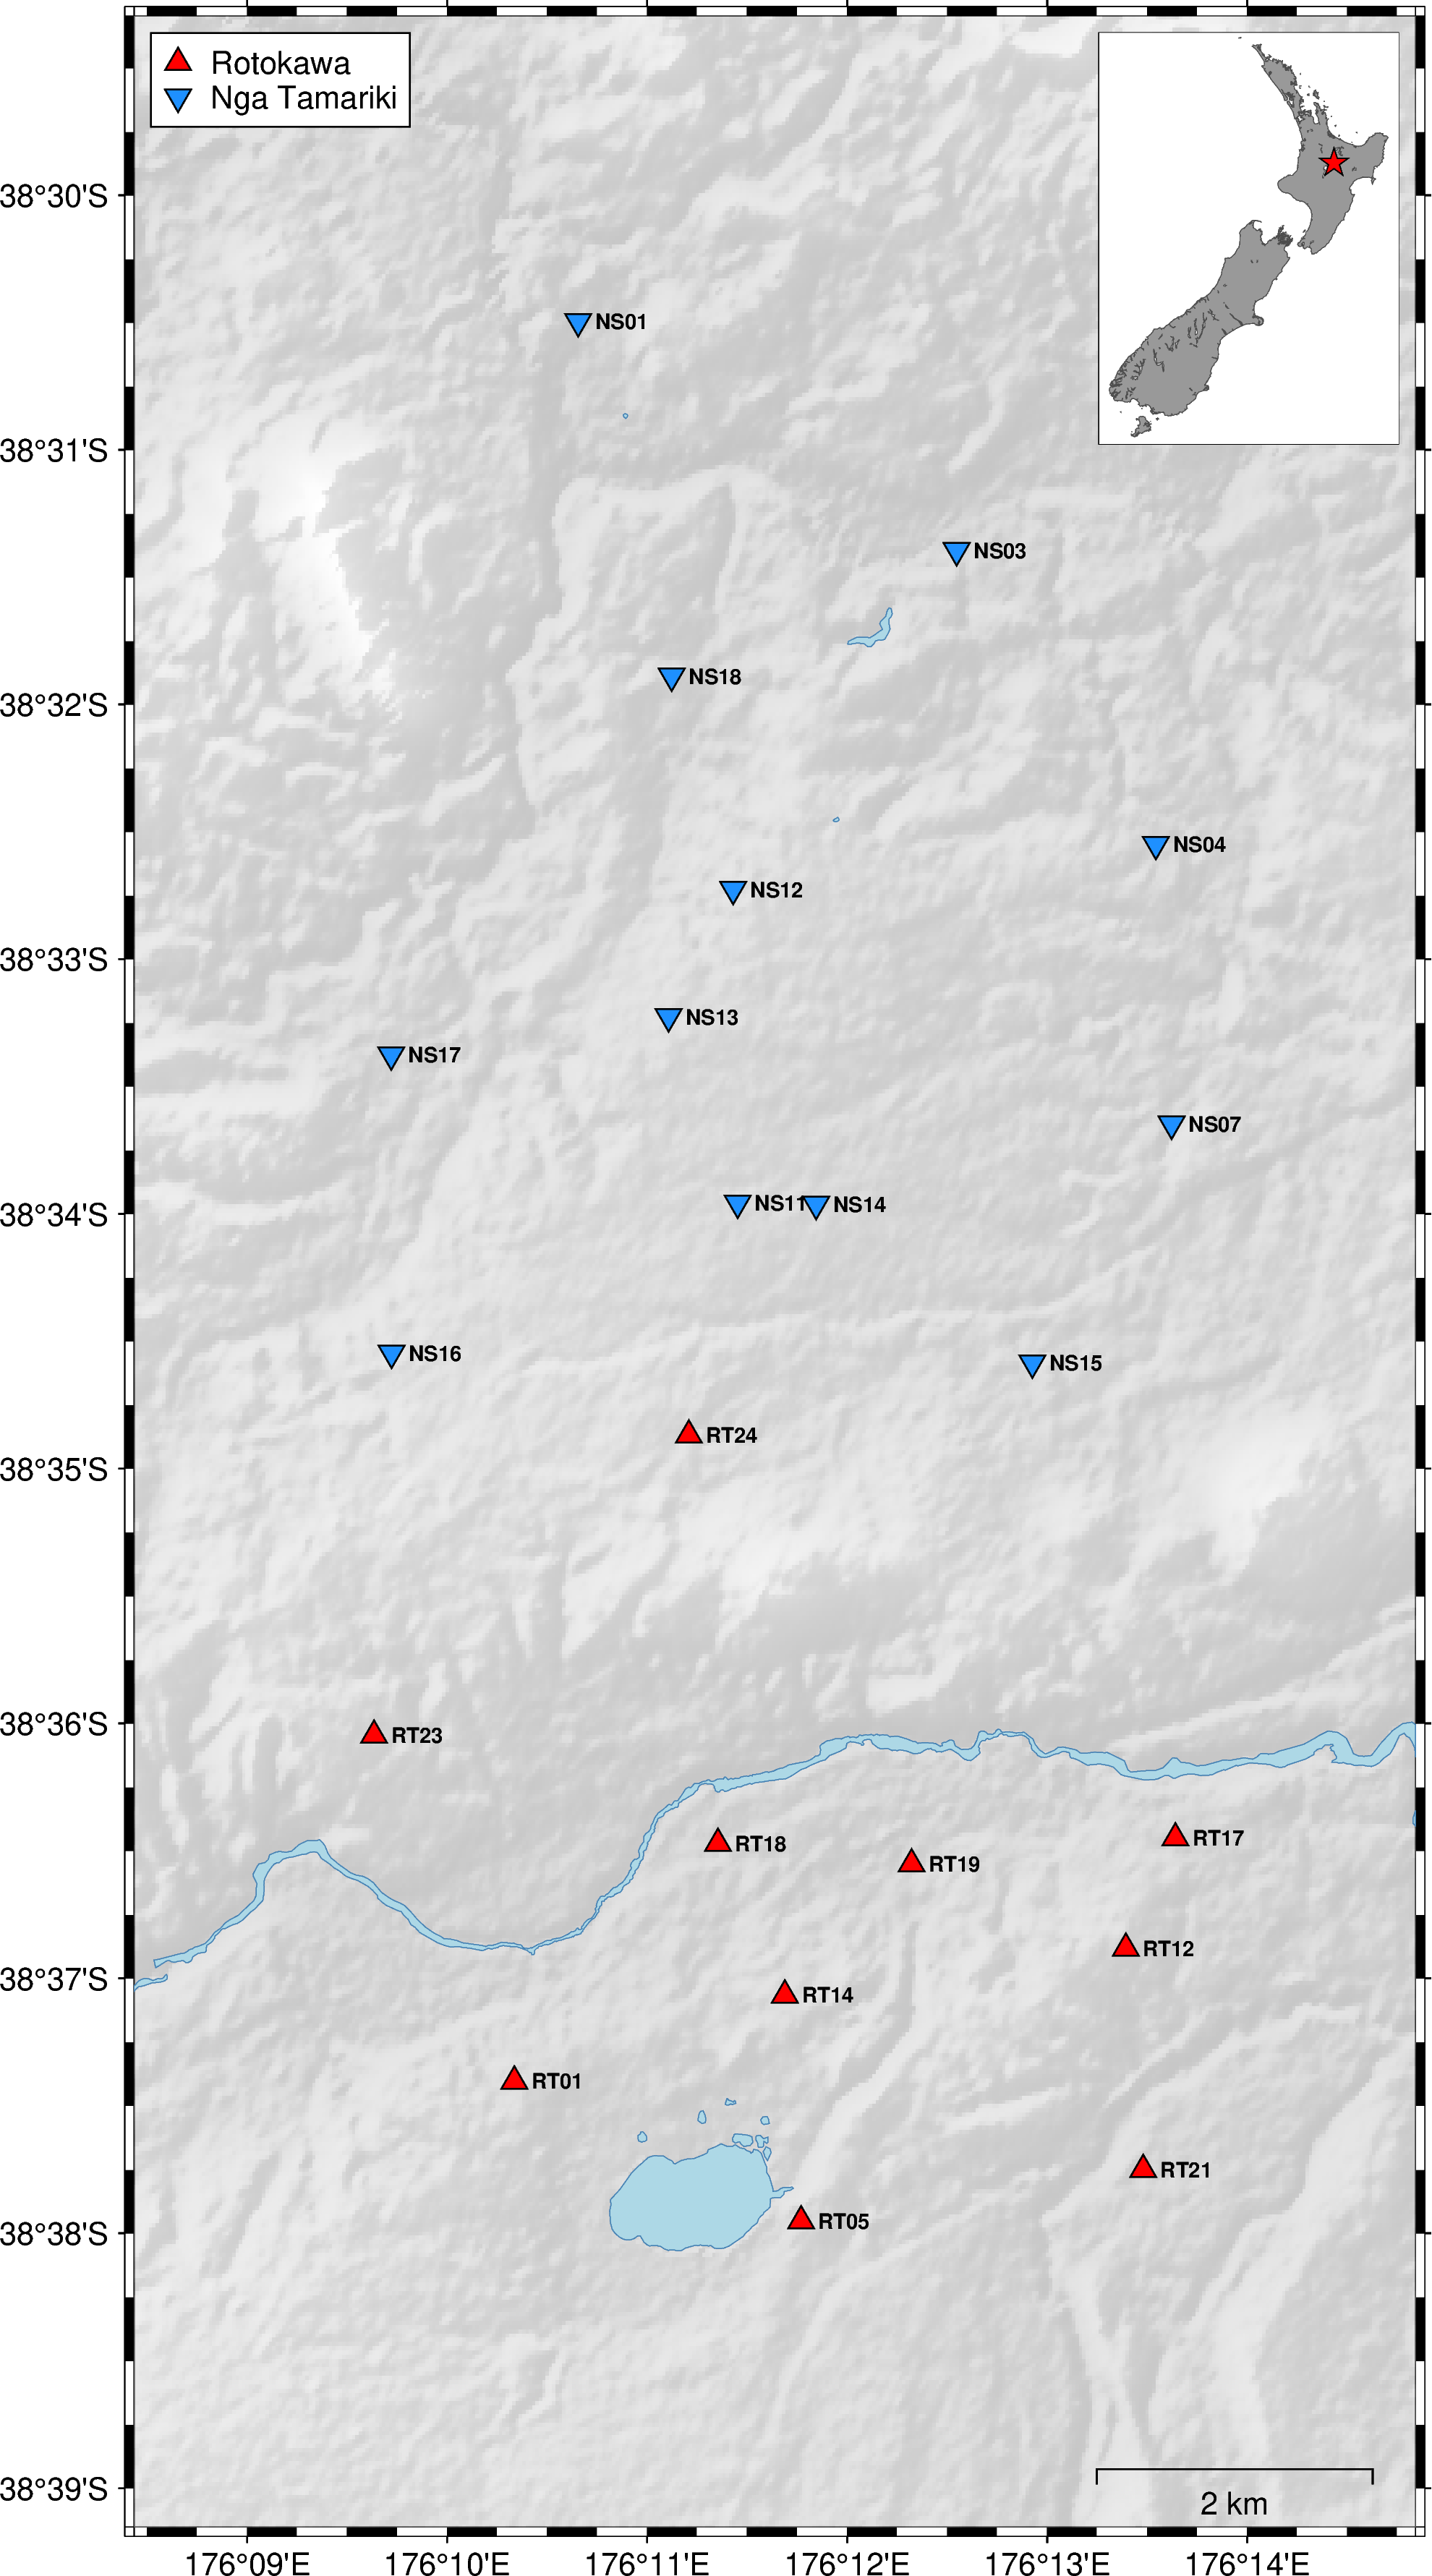

In [2]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import pygmt
from pyproj import Transformer

DATA = Path("../data")
FIGURES = Path("../figures")
STATIONS = DATA / "RTK_NTM_Station_Coordinates.dat"
FIG_OUT = FIGURES / "current_stations_map.png"
CPT = DATA / "topo_gray.cpt"

rows = []
for line in STATIONS.read_text().splitlines()[2:]:
    parts = line.split()
    if len(parts) < 4:
        continue
    rows.append({"field": " ".join(parts[:-3]), "station": parts[-3],
                 "x": float(parts[-2]), "y": float(parts[-1])})
df = pd.DataFrame(rows)

to_wgs84 = Transformer.from_crs("EPSG:2193", "EPSG:4326", always_xy=True)
df["lon"], df["lat"] = to_wgs84.transform(df["x"].values, df["y"].values)

pad = 0.02
region = [df.lon.min() - pad, df.lon.max() + pad,
          df.lat.min() - pad, df.lat.max() + pad]
grid = pygmt.datasets.load_earth_relief(resolution="01s", region=region)

zmin, zmax = float(grid.min()), float(grid.max())
pygmt.makecpt(cmap="gray", series=[zmin - (zmax - zmin), zmax], output=str(CPT))

fig = pygmt.Figure()
fig.basemap(region=region, projection="M15c", frame=["WSne", "af"])
fig.grdimage(grid=grid, cmap=str(CPT), shading="+a315+ne0.4", transparency=60)

bbox = (df.x.min() - 3000, df.y.min() - 3000, df.x.max() + 3000, df.y.max() + 3000)
for shp in ["nz-lake-polygons-topo-150k.shp", "nz-river-polygons-topo-150k.shp"]:
    water = gpd.read_file(DATA / shp, bbox=bbox).to_crs("EPSG:4326")
    water = water.clip((region[0], region[2], region[1], region[3]))
    if not water.empty:
        fig.plot(data=water, fill="lightblue", pen="0.25p,steelblue")

styles = {"Rotokawa": ("t0.35c", "red"),
          "Nga Tamariki": ("i0.35c", "dodgerblue")}
for field, (symbol, colour) in styles.items():
    sub = df[df.field == field]
    fig.plot(x=sub.lon, y=sub.lat, style=symbol, fill=colour,
             pen="0.5p,black", label=field)
    fig.text(x=sub.lon, y=sub.lat, text=sub.station.tolist(),
             font="7p,Helvetica-Bold,black", justify="LM", offset="0.2c/0c")

fig.legend(position="JTL+jTL+o0.2c", box="+gwhite+p0.5p")
fig.basemap(map_scale="jBR+o0.5c/0.5c+w2k")

lon_c = (region[0] + region[1]) / 2
lat_c = (region[2] + region[3]) / 2
with fig.inset(position="jTR+o0.2c", box="+gwhite+p0.5p",
               region=[166, 179, -47.5, -34], projection="M3.5c"):
    fig.coast(land="gray60", water="white", shorelines="0.2p,gray30",
              resolution="i")
    fig.plot(x=lon_c, y=lat_c, style="a0.35c", fill="red", pen="0.3p,black")

fig.savefig(FIG_OUT, dpi=300)
fig.show()